device=cpu  seeds=5

== breast_cancer (clf, 569 samples, 30 features)  widths={'MLP': 56, 'KAN': 17, 'FreqKAN': 11}
  seed 1/5 done  (17s)
  seed 2/5 done  (19s)
  seed 3/5 done  (21s)
  seed 4/5 done  (24s)
  seed 5/5 done  (26s)

== wine (clf, 178 samples, 13 features)  widths={'MLP': 62, 'KAN': 34, 'FreqKAN': 17}
  seed 1/5 done  (28s)
  seed 2/5 done  (29s)
  seed 3/5 done  (30s)
  seed 4/5 done  (32s)
  seed 5/5 done  (33s)

== california_housing (reg, 20640 samples, 8 features)  widths={'MLP': 65, 'KAN': 59, 'FreqKAN': 21}
  seed 1/5 done  (56s)
  seed 2/5 done  (78s)
  seed 3/5 done  (99s)
  seed 4/5 done  (120s)
  seed 5/5 done  (141s)

== covertype (clf, 20000 samples, 54 features)  widths={'MLP': 46, 'KAN': 9, 'FreqKAN': 6}
  seed 1/5 done  (226s)
  seed 2/5 done  (251s)
  seed 3/5 done  (276s)
  seed 4/5 done  (301s)
  seed 5/5 done  (326s)

== adult (clf, 20000 samples, 105 features)  widths={'MLP': 35, 'KAN': 5, 'FreqKAN': 4}
  seed 1/5 done  (364s)
  seed 2/5 done  (397s)

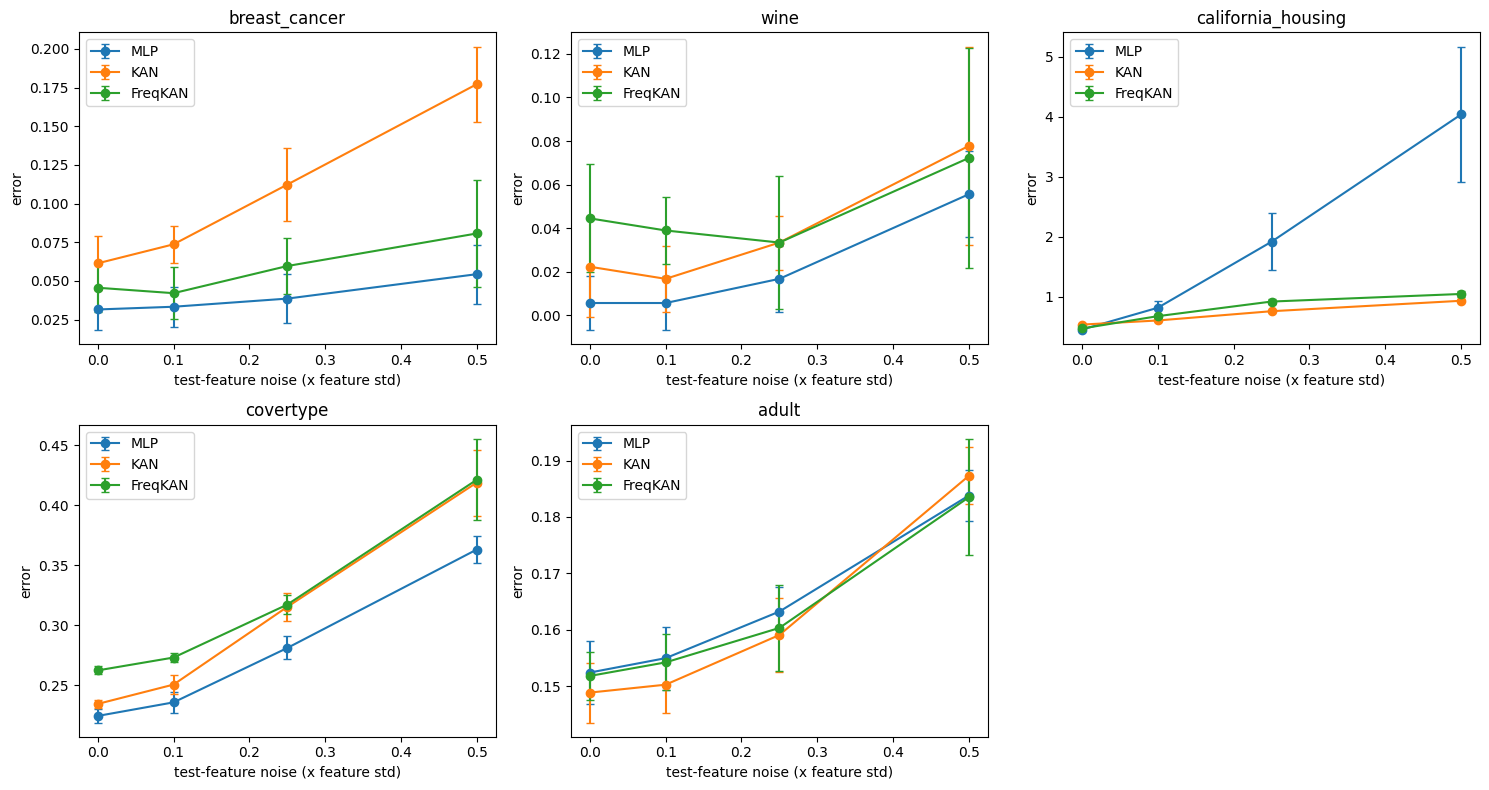


Done in 491s. Saved results_raw.csv, results_table.csv, robustness.png


In [ ]:
"""
KAN vs MLP vs Frequency-Aware KAN under Noise and Distribution Shift
(Extension of Zeng et al., "KAN versus MLP on Irregular or Noisy Functions", arXiv 2408.07906)

Colab:   !python kan_vs_mlp_robustness.py        (5 seeds, full)
         !python kan_vs_mlp_robustness.py 2      (2 seeds, quick test)
Outputs: results_raw.csv, results_table.csv, robustness.png
All models are matched to ~the same parameter count. Metric = error (lower is better):
  classification -> 1 - accuracy ; regression -> RMSE on standardized target.
"""
import sys, time, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_breast_cancer, load_wine, fetch_california_housing, load_diabetes, fetch_covtype, fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

dev = "cuda" if torch.cuda.is_available() else "cpu"
SEEDS = int(sys.argv[1]) if len(sys.argv) > 1 and sys.argv[1].isdigit() else 5
PARAM_TARGET = 5000
NOISE_LEVELS = [0.1, 0.25, 0.5]          # noise std as a fraction of feature std (features are standardized)
EPOCHS = {"breast_cancer": 80, "wine": 120, "california_housing": 30, "covertype": 30, "adult": 30}
DATASETS = ["breast_cancer", "wine", "california_housing", "covertype", "adult"]
BIG_N = 20000   # subsample size for the large datasets
BATCH, LR = 256, 3e-3

# ---------------------------------------------------------------- data
def load(name):
    if name == "breast_cancer": d = load_breast_cancer(); return d.data, d.target, "clf"
    if name == "wine":          d = load_wine();          return d.data, d.target, "clf"
    if name == "california_housing":
        try: d = fetch_california_housing()
        except Exception as e:
            print("  (california download failed -> using diabetes instead)", e); d = load_diabetes()
        return d.data, d.target, "reg"
    if name == "covertype":
        d = fetch_covtype(); X, y = d.data, d.target - d.target.min()
        i, _ = train_test_split(np.arange(len(X)), train_size=BIG_N, random_state=0, stratify=y)
        return X[i].astype(np.float64), y[i], "clf"
    if name == "adult":
        d = fetch_openml("adult", version=2, as_frame=True, parser="auto")
        df = d.data.copy(); df["y"] = (d.target.astype(str).str.strip().str.contains(">50K")).astype(int)
        df = df.dropna()
        y = df.pop("y").values; X = pd.get_dummies(df).astype(np.float64).values
        i, _ = train_test_split(np.arange(len(X)), train_size=BIG_N, random_state=0, stratify=y)
        return X[i], y[i], "clf"

def make_split(X, y, task, kind, seed):
    """kind='random': 80/20 random split.  kind='shift': train on lowest 70% of PC1, test on highest 30%."""
    if kind == "random":
        idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=seed,
                                          stratify=y if task == "clf" else None)
    else:
        z = PCA(1, random_state=0).fit_transform(StandardScaler().fit_transform(X))[:, 0]
        order = np.argsort(z); cut = int(0.7 * len(X)); idx_tr, idx_te = order[:cut], order[cut:]
    idx_tr, idx_va = train_test_split(idx_tr, test_size=0.1, random_state=seed)
    sc = StandardScaler().fit(X[idx_tr])                     # fit scaler on TRAIN only
    T = lambda a: torch.tensor(sc.transform(a), dtype=torch.float32, device=dev)
    out = {"Xtr": T(X[idx_tr]), "Xva": T(X[idx_va]), "Xte": T(X[idx_te])}
    if task == "clf":
        L = lambda i: torch.tensor(y[i], dtype=torch.long, device=dev)
        out.update(ytr=L(idx_tr), yva=L(idx_va), yte=L(idx_te))
    else:
        m, s = y[idx_tr].mean(), y[idx_tr].std() + 1e-8
        L = lambda i: torch.tensor((y[i] - m) / s, dtype=torch.float32, device=dev).unsqueeze(1)
        out.update(ytr=L(idx_tr), yva=L(idx_va), yte=L(idx_te))
    return out

# ---------------------------------------------------------------- models
class KANLayer(nn.Module):
    """FastKAN-style layer: learnable RBF basis expansion + SiLU base path."""
    def __init__(s, i, o, g=8):
        super().__init__()
        s.ln = nn.LayerNorm(i)
        s.register_buffer("c", torch.linspace(-2, 2, g))
        s.base = nn.Linear(i, o); s.spl = nn.Linear(i * g, o, bias=False)
    def forward(s, x):
        x = s.ln(x)
        phi = torch.exp(-((x[..., None] - s.c) / 0.5) ** 2).flatten(-2)
        return s.base(F.silu(x)) + s.spl(phi)

class FourierFeatures(nn.Module):
    """Learnable Fourier features: [x, sin(xB), cos(xB)]  -> gives the KAN explicit frequency information."""
    def __init__(s, d, k=8):
        super().__init__(); s.B = nn.Parameter(torch.randn(d, k))
    def forward(s, x):
        z = x @ s.B
        return torch.cat([x, torch.sin(z), torch.cos(z)], -1)

def build(kind, d_in, d_out, h):
    if kind == "MLP":
        return nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, d_out))
    if kind == "KAN":
        return nn.Sequential(KANLayer(d_in, h), KANLayer(h, d_out))
    if kind == "FreqKAN":
        return nn.Sequential(FourierFeatures(d_in, 8), KANLayer(d_in + 16, h), KANLayer(h, d_out))

def n_params(m): return sum(p.numel() for p in m.parameters())

def matched_width(kind, d_in, d_out, target=PARAM_TARGET):
    best = min(range(2, 300), key=lambda h: abs(n_params(build(kind, d_in, d_out, h)) - target))
    return best

# ---------------------------------------------------------------- train / eval
def loss_fn(out, y, task): return F.cross_entropy(out, y) if task == "clf" else F.mse_loss(out, y)

def error(model, X, y, task):
    model.eval()
    with torch.no_grad():
        o = model(X)
        return (o.argmax(1) != y).float().mean().item() if task == "clf" else torch.sqrt(F.mse_loss(o, y)).item()

def fit(model, D, task, epochs):
    opt = torch.optim.AdamW(model.parameters(), LR, weight_decay=1e-4)
    best, state = 1e9, None
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(D["Xtr"]), device=dev)
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = loss_fn(model(D["Xtr"][b]), D["ytr"][b], task)
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): v = loss_fn(model(D["Xva"]), D["yva"], task).item()
        if v < best: best, state = v, {k: x.clone() for k, x in model.state_dict().items()}
    model.load_state_dict(state); return model

# ---------------------------------------------------------------- experiment
def main():
    print(f"device={dev}  seeds={SEEDS}"); rows = []; t0 = time.time()
    for name in DATASETS:
        try: X, y, task = load(name)
        except Exception as e:
            print(f"\n== {name}: SKIPPED (could not load: {e})"); continue
        d_in = X.shape[1]; d_out = len(np.unique(y)) if task == "clf" else 1
        widths = {k: matched_width(k, d_in, d_out) for k in ["MLP", "KAN", "FreqKAN"]}
        print(f"\n== {name} ({task}, {len(X)} samples, {d_in} features)  widths={widths}")
        for seed in range(SEEDS):
            for kind in ["random", "shift"]:
                D = make_split(X, y, task, kind, seed)
                for mk in ["MLP", "KAN", "FreqKAN"]:
                    torch.manual_seed(seed)
                    m = build(mk, d_in, d_out, widths[mk]).to(dev)
                    p = n_params(m); m = fit(m, D, task, EPOCHS[name])
                    if kind == "random":
                        rows.append((name, "clean", mk, seed, error(m, D["Xte"], D["yte"], task), p))
                        for s in NOISE_LEVELS:
                            g = torch.Generator(device=dev).manual_seed(1000 + seed)
                            Xn = D["Xte"] + s * torch.randn(D["Xte"].shape, device=dev, generator=g)
                            rows.append((name, f"noise {s}", mk, seed, error(m, Xn, D["yte"], task), p))
                    else:
                        rows.append((name, "dist. shift", mk, seed, error(m, D["Xte"], D["yte"], task), p))
            print(f"  seed {seed + 1}/{SEEDS} done  ({time.time() - t0:.0f}s)", flush=True)

    raw = pd.DataFrame(rows, columns=["dataset", "condition", "model", "seed", "error", "params"])
    raw.to_csv("results_raw.csv", index=False)
    g = raw.groupby(["dataset", "condition", "model"]).agg(mean=("error", "mean"), std=("error", "std"),
                                                            params=("params", "first")).reset_index()
    order = ["clean"] + [f"noise {s}" for s in NOISE_LEVELS] + ["dist. shift"]
    table = []
    for (ds, cond), grp in g.groupby(["dataset", "condition"]):
        r = {"dataset": ds, "condition": cond}
        for _, row in grp.iterrows(): r[row["model"]] = f"{row['mean']:.4f} ± {row['std']:.4f}"
        r["winner"] = grp.loc[grp["mean"].idxmin(), "model"]; table.append(r)
    table = pd.DataFrame(table)
    table["condition"] = pd.Categorical(table["condition"], order, ordered=True)
    table = table.sort_values(["dataset", "condition"])[["dataset", "condition", "MLP", "KAN", "FreqKAN", "winner"]]
    table.to_csv("results_table.csv", index=False)
    print("\nPARAMS:", raw.groupby("model")["params"].mean().round().to_dict())
    print("\n", table.to_string(index=False))

    import matplotlib.pyplot as plt
    names = list(raw["dataset"].unique()); ncol = 3; nrow = -(-len(names) // ncol)
    fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow)); axs = np.atleast_1d(axs).flatten()
    for extra in axs[len(names):]: extra.axis("off")
    xs = [0] + NOISE_LEVELS; conds = ["clean"] + [f"noise {s}" for s in NOISE_LEVELS]
    for ax, ds in zip(axs, names):
        for mk in ["MLP", "KAN", "FreqKAN"]:
            sub = g[(g.dataset == ds) & (g.model == mk)].set_index("condition").loc[conds]
            ax.errorbar(xs, sub["mean"], yerr=sub["std"], marker="o", capsize=3, label=mk)
        ax.set_title(ds); ax.set_xlabel("test-feature noise (x feature std)"); ax.set_ylabel("error"); ax.legend()
    plt.tight_layout(); plt.savefig("robustness.png", dpi=150); plt.show()
    print(f"\nDone in {time.time() - t0:.0f}s. Saved results_raw.csv, results_table.csv, robustness.png")

if __name__ == "__main__":
    main()
